In [24]:
# ============================================================
Import all required libraries
# ============================================================
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import re, string, pickle
from collections import Counter
from wordcloud import WordCloud
import nltk
from nltk.corpus import stopwords
from nltk.tokenize import word_tokenize
from nltk.stem import WordNetLemmatizer
import emoji
# If 'internet_words_remover' is not installed, you may need a custom chat‑words mapping
from internet_words_remover import words_remover
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer
from sklearn.model_selection import train_test_split
from scipy.sparse import hstack

# Download NLTK resources (if not already done)
nltk.download('punkt', quiet=True)
nltk.download('stopwords', quiet=True)
nltk.download('wordnet', quiet=True)
nltk.download('omw-1.4', quiet=True)
nltk.download('averaged_perceptron_tagger_eng', quiet=True)

# Plot settings
sns.set_style('whitegrid')
%matplotlib inline

In [26]:
# Cell 1: Load and combine the TSV files with proper column names
import pandas as pd

# Define column names exactly as requested
col_names = [
    'ID',                    # 1. ID
    'label',                 # 2. label
    'title',                 # 3. title (statement)
    'subject',               # 4. subject
    'speaker',               # 5. speaker
    'speaker_job',           # 6. speaker's job
    'state',                 # 7. state
    'party',                 # 8. party
    'barely_true_counts',    # 9. barely true counts
    'false_counts',          # 10. false counts
    'half_true_counts',      # 11. half true counts
    'mostly_true_counts',    # 12. mostly true counts
    'pants_on_fire_counts',  # 13. pants on fire counts
    'context'                # 14. context / venue
]

# Read the files without header and assign the column names
train = pd.read_csv('train.tsv', sep='\t', header=None, names=col_names)
test  = pd.read_csv('test.tsv',  sep='\t', header=None, names=col_names)
valid = pd.read_csv('valid.tsv', sep='\t', header=None, names=col_names)

print("Train shape:", train.shape)
print("Test shape :", test.shape)
print("Valid shape:", valid.shape)

# Combine them into one master DataFrame
df_raw = pd.concat([train, test, valid], ignore_index=True)
print("\nCombined shape:", df_raw.shape)
df_raw.head()

Train shape: (10240, 14)
Test shape : (1267, 14)
Valid shape: (1284, 14)

Combined shape: (12791, 14)


,ID,label,title,subject,speaker,speaker_job,state,party,barely_true_counts,false_counts,half_true_counts,mostly_true_counts,pants_on_fire_counts,context
0,2635.json,false,Says the Annies List political group supports ...,abortion,dwayne-bohac,State representative,Texas,republican,0.0,1.0,0.0,0.0,0.0,a mailer
1,10540.json,half-true,When did the decline of coal start? It started...,"energy,history,job-accomplishments",scott-surovell,State delegate,Virginia,democrat,0.0,0.0,1.0,1.0,0.0,a floor speech.
2,324.json,mostly-true,"Hillary Clinton agrees with John McCain ""by vo...",foreign-policy,barack-obama,President,Illinois,democrat,70.0,71.0,160.0,163.0,9.0,Denver
3,1123.json,false,Health care reform legislation is likely to ma...,health-care,blog-posting,NaN,NaN,none,7.0,19.0,3.0,5.0,44.0,a news release
4,9028.json,half-true,The economic turnaround started at the end of ...,"economy,jobs",charlie-crist,NaN,Florida,democrat,15.0,9.0,20.0,19.0,2.0,an interview on CNN


In [28]:
df_raw.to_csv('LIAR.csv', index=False)

In [30]:
# Check column names and a few rows
print("Columns:", df_raw.columns.tolist())
display(df_raw.head(2))

# Look at unique labels
print("\nOriginal labels and counts:")
print(df_raw['label'].value_counts())

Columns: ['ID', 'label', 'title', 'subject', 'speaker', 'speaker_job', 'state', 'party', 'barely_true_counts', 'false_counts', 'half_true_counts', 'mostly_true_counts', 'pants_on_fire_counts', 'context']


,ID,label,title,subject,speaker,speaker_job,state,party,barely_true_counts,false_counts,half_true_counts,mostly_true_counts,pants_on_fire_counts,context
0,2635.json,false,Says the Annies List political group supports ...,abortion,dwayne-bohac,State representative,Texas,republican,0.0,1.0,0.0,0.0,0.0,a mailer
1,10540.json,half-true,When did the decline of coal start? It started...,"energy,history,job-accomplishments",scott-surovell,State delegate,Virginia,democrat,0.0,0.0,1.0,1.0,0.0,a floor speech.



Original labels and counts:
label
half-true      2627
false          2507
mostly-true    2454
barely-true    2103
true           2053
pants-fire     1047
Name: count, dtype: int64


In [32]:
# Define mapping (customable)
fake_labels = ['pants-fire', 'false', 'barely-true']
real_labels = ['half-true', 'mostly-true', 'true']

def map_label(x):
    if x in fake_labels:
        return 1
    elif x in real_labels:
        return 0
    else:
        return None   # discard unknown

df_raw['label_binary'] = df_raw['label'].apply(map_label)

# Drop rows with unknown labels (if any)
df_raw = df_raw.dropna(subset=['label_binary']).copy()
df_raw['label'] = df_raw['label_binary'].astype(int)
df_raw.drop(columns=['label_binary'], inplace=True)

print("After mapping:")
print(df_raw['label'].value_counts())

After mapping:
label
0    7134
1    5657
Name: count, dtype: int64


In [34]:
# Cell 4: Quick look at the data after label mapping
# We'll work directly with df_raw (already has 'label' as 0/1)
print("Fake news shape:", df_raw[df_raw['label'] == 1].shape)
print("Real news shape:", df_raw[df_raw['label'] == 0].shape)

print("\nFake news columns:", df_raw.columns.tolist())
print("Real news columns:", df_raw.columns.tolist())

# Show a couple of examples
display(df_raw[df_raw['label'] == 1].head(2))
display(df_raw[df_raw['label'] == 0].head(2))

Fake news shape: (5657, 14)
Real news shape: (7134, 14)

Fake news columns: ['ID', 'label', 'title', 'subject', 'speaker', 'speaker_job', 'state', 'party', 'barely_true_counts', 'false_counts', 'half_true_counts', 'mostly_true_counts', 'pants_on_fire_counts', 'context']
Real news columns: ['ID', 'label', 'title', 'subject', 'speaker', 'speaker_job', 'state', 'party', 'barely_true_counts', 'false_counts', 'half_true_counts', 'mostly_true_counts', 'pants_on_fire_counts', 'context']


,ID,label,title,subject,speaker,speaker_job,state,party,barely_true_counts,false_counts,half_true_counts,mostly_true_counts,pants_on_fire_counts,context
0,2635.json,1,Says the Annies List political group supports ...,abortion,dwayne-bohac,State representative,Texas,republican,0.0,1.0,0.0,0.0,0.0,a mailer
3,1123.json,1,Health care reform legislation is likely to ma...,health-care,blog-posting,NaN,NaN,none,7.0,19.0,3.0,5.0,44.0,a news release


,ID,label,title,subject,speaker,speaker_job,state,party,barely_true_counts,false_counts,half_true_counts,mostly_true_counts,pants_on_fire_counts,context
1,10540.json,0,When did the decline of coal start? It started...,"energy,history,job-accomplishments",scott-surovell,State delegate,Virginia,democrat,0.0,0.0,1.0,1.0,0.0,a floor speech.
2,324.json,0,"Hillary Clinton agrees with John McCain ""by vo...",foreign-policy,barack-obama,President,Illinois,democrat,70.0,71.0,160.0,163.0,9.0,Denver


In [36]:
# Cell 5: Data types and missing values overview
print("=== df_raw info ===")
df_raw.info()
print("\nMissing values per column:")
print(df_raw.isnull().sum())

=== df_raw info ===
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 12791 entries, 0 to 12790
Data columns (total 14 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   ID                    12791 non-null  object 
 1   label                 12791 non-null  int64  
 2   title                 12791 non-null  object 
 3   subject               12789 non-null  object 
 4   speaker               12789 non-null  object 
 5   speaker_job           9223 non-null   object 
 6   state                 10040 non-null  object 
 7   party                 12789 non-null  object 
 8   barely_true_counts    12789 non-null  float64
 9   false_counts          12789 non-null  float64
 10  half_true_counts      12789 non-null  float64
 11  mostly_true_counts    12789 non-null  float64
 12  pants_on_fire_counts  12789 non-null  float64
 13  context               12660 non-null  object 
dtypes: float64(5), int64(1), object(8)
memory usage: 1

In [38]:
# Cell 6: Combine, shuffle, and create master DataFrame
df = df_raw.sample(frac=1, random_state=42).reset_index(drop=True)
print("Combined dataset shape:", df.shape)
display(df.head(3))

Combined dataset shape: (12791, 14)


,ID,label,title,subject,speaker,speaker_job,state,party,barely_true_counts,false_counts,half_true_counts,mostly_true_counts,pants_on_fire_counts,context
0,8250.json,1,"In the event of a U.S. strike on Syria, the Ru...","foreign-policy,military",alan-grayson,U.S. House of Representatives,Florida,democrat,6.0,5.0,4.0,11.0,1.0,"an interview with the ""Washington Post"""
1,923.json,0,To give the proposed economic stimulus plan so...,"economy,stimulus",mitch-mcconnell,Senate minority leader,Kentucky,republican,7.0,6.0,5.0,7.0,0.0,"appearance on CBS's ""Face the Nation"""
2,8736.json,1,Its warmer on Mars than it is in parts of the ...,"space,weather",tweets,NaN,NaN,none,2.0,3.0,1.0,2.0,3.0,posts on Twitter


In [40]:
# Cell 7: Identify main text column (the statement is in 'title')
text_col = 'title'
print("Text column:", text_col)

Text column: title


In [42]:
# Cell 8: Keep only title and label
print("Missing values per column before drop:")
print(df.isnull().sum())

# Drop all columns except title and label
columns_to_keep = ['title', 'label']
df = df[columns_to_keep].copy()
print("\nAfter dropping unnecessary columns:")
print(df.isnull().sum())
df.head()

Missing values per column before drop:
ID                         0
label                      0
title                      0
subject                    2
speaker                    2
speaker_job             3568
state                   2751
party                      2
barely_true_counts         2
false_counts               2
half_true_counts           2
mostly_true_counts         2
pants_on_fire_counts       2
context                  131
dtype: int64

After dropping unnecessary columns:
title    0
label    0
dtype: int64


,title,label
0,"In the event of a U.S. strike on Syria, the Ru...",1
1,To give the proposed economic stimulus plan so...,0
2,Its warmer on Mars than it is in parts of the ...,1
3,The health insurance plan that (members of Con...,0
4,He's promising four more years of an administr...,1


/var/folders/z3/4jxjt96505s9lmct58gkr4lr0000gn/T/ipykernel_52191/3117622208.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(x='label', data=df, palette='Set2')


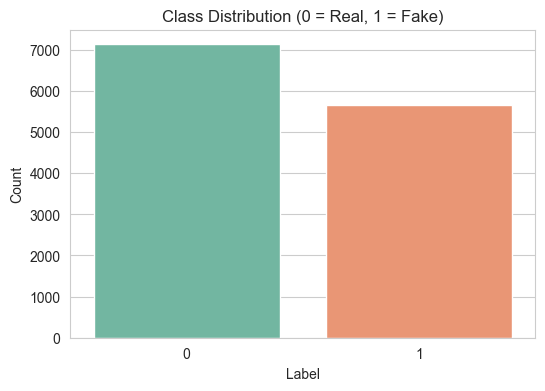

Label counts:
 label
0    7134
1    5657
Name: count, dtype: int64


In [44]:
# Cell 9: Class distribution
plt.figure(figsize=(6,4))
sns.countplot(x='label', data=df, palette='Set2')
plt.title('Class Distribution (0 = Real, 1 = Fake)')
plt.xlabel('Label')
plt.ylabel('Count')
plt.show()
print("Label counts:\n", df['label'].value_counts())

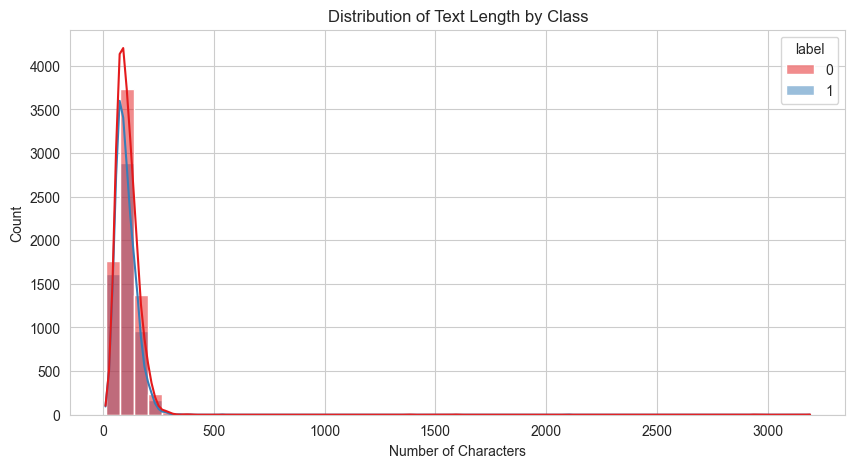

Text length statistics by label:
        count        mean        std   min   25%    50%    75%     max
label                                                                 
0      7134.0  109.633445  70.986881  11.0  75.0  101.0  135.0  3192.0
1      5657.0  104.044193  52.268197  11.0  71.0   95.0  130.0  2099.0


In [58]:
# Cell 10: Text length analysis
df['text_len'] = df[text_col].astype(str).apply(len)

plt.figure(figsize=(10,5))
sns.histplot(data=df, x='text_len', hue='label', bins=50, kde=True, palette='Set1')
plt.title('Distribution of Text Length by Class')
plt.xlabel('Number of Characters')
plt.show()

print("Text length statistics by label:")
print(df.groupby('label')['text_len'].describe())

/var/folders/z3/4jxjt96505s9lmct58gkr4lr0000gn/T/ipykernel_52191/3913268402.py:5: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x='label', y='word_count', data=df, palette='Set3')


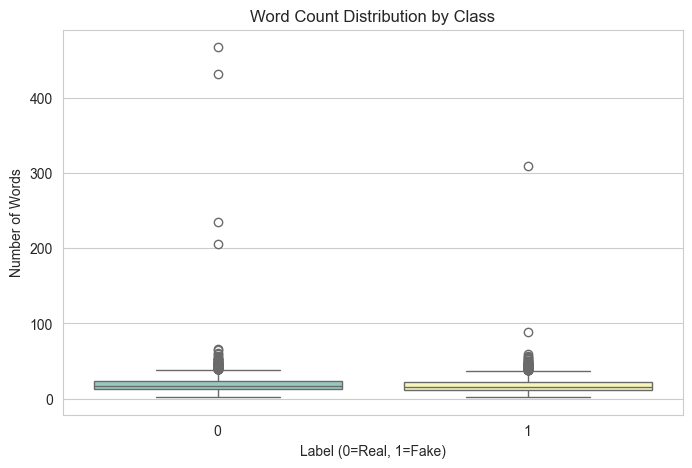

Word count statistics by label:
        count       mean        std  min   25%   50%   75%    max
label                                                            
0      7134.0  18.535464  11.165430  2.0  13.0  17.0  23.0  467.0
1      5657.0  17.416475   8.607552  2.0  12.0  16.0  22.0  309.0


In [52]:
# Cell 11: Word count analysis
df['word_count'] = df[text_col].astype(str).apply(lambda x: len(x.split()))

plt.figure(figsize=(8,5))
sns.boxplot(x='label', y='word_count', data=df, palette='Set3')
plt.title('Word Count Distribution by Class')
plt.xlabel('Label (0=Real, 1=Fake)')
plt.ylabel('Number of Words')
plt.show()

print("Word count statistics by label:")
print(df.groupby('label')['word_count'].describe())

/var/folders/z3/4jxjt96505s9lmct58gkr4lr0000gn/T/ipykernel_52191/1984756284.py:5: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x='label', y='unique_words', data=df, palette='pastel')


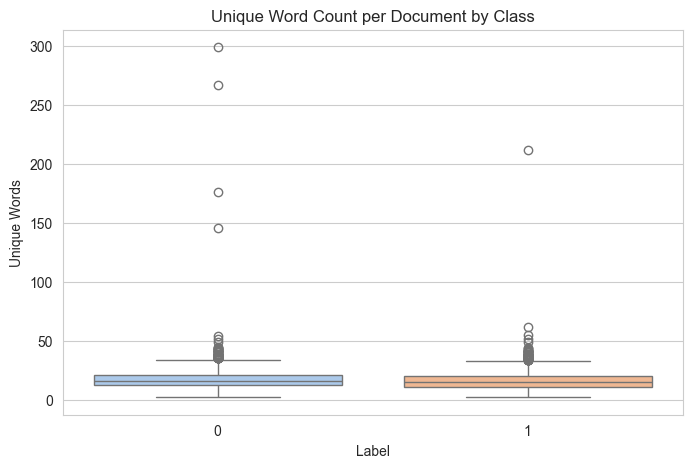

Unique word count statistics by label:
        count       mean       std  min   25%   50%   75%    max
label                                                           
0      7134.0  16.994814  8.205502  2.0  12.0  16.0  21.0  299.0
1      5657.0  16.207354  7.000856  2.0  11.0  15.0  20.0  212.0


In [54]:
# Cell 12: Unique word count per document
df['unique_words'] = df[text_col].astype(str).apply(lambda x: len(set(x.lower().split())))

plt.figure(figsize=(8,5))
sns.boxplot(x='label', y='unique_words', data=df, palette='pastel')
plt.title('Unique Word Count per Document by Class')
plt.xlabel('Label')
plt.ylabel('Unique Words')
plt.show()

print("Unique word count statistics by label:")
print(df.groupby('label')['unique_words'].describe())

In [62]:
# Cell 13: Most frequent words after removing stopwords
import nltk
from nltk.corpus import stopwords
from nltk.tokenize import word_tokenize
from collections import Counter

nltk.download('punkt', quiet=True)
nltk.download('stopwords', quiet=True)

stop_words = set(stopwords.words('english'))

def get_top_words(text_series, n_top=20):
    all_text = ' '.join(text_series.astype(str))
    words = all_text.lower().split()
    # Keep only alphabetic tokens and remove stopwords
    words = [w for w in words if w.isalpha() and w not in stop_words]
    return Counter(words).most_common(n_top)

print("Top 20 words in FAKE news:")
print(get_top_words(df[df['label'] == 1][text_col]))

print("\nTop 20 words in REAL news:")
print(get_top_words(df[df['label'] == 0][text_col]))

Top 20 words in FAKE news:
[('says', 1439), ('obama', 427), ('health', 386), ('percent', 356), ('president', 356), ('state', 327), ('tax', 317), ('care', 310), ('people', 289), ('would', 288), ('barack', 252), ('new', 241), ('voted', 219), ('one', 215), ('bill', 211), ('million', 200), ('federal', 195), ('billion', 193), ('said', 186), ('states', 183)]

Top 20 words in REAL news:
[('says', 1516), ('percent', 853), ('state', 535), ('tax', 419), ('people', 379), ('million', 374), ('would', 359), ('health', 353), ('new', 348), ('obama', 342), ('one', 327), ('since', 316), ('states', 308), ('president', 300), ('every', 295), ('federal', 268), ('jobs', 261), ('last', 257), ('year', 247), ('texas', 241)]


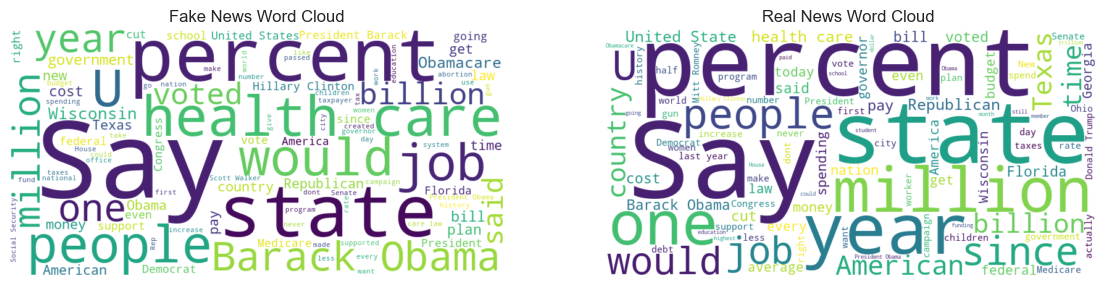

In [64]:
# Cell 14: Word clouds
from wordcloud import WordCloud

fake_text = ' '.join(df[df['label'] == 1][text_col].astype(str))
real_text = ' '.join(df[df['label'] == 0][text_col].astype(str))

wc_fake = WordCloud(stopwords=stop_words, max_words=100, background_color='white',
                    width=800, height=400, random_state=42).generate(fake_text)
wc_real = WordCloud(stopwords=stop_words, max_words=100, background_color='white',
                    width=800, height=400, random_state=42).generate(real_text)

plt.figure(figsize=(14,7))
plt.subplot(1,2,1)
plt.imshow(wc_fake, interpolation='bilinear')
plt.title('Fake News Word Cloud')
plt.axis('off')

plt.subplot(1,2,2)
plt.imshow(wc_real, interpolation='bilinear')
plt.title('Real News Word Cloud')
plt.axis('off')
plt.show()

In [66]:
# Cell 15: Top bigrams for each class
from sklearn.feature_extraction.text import CountVectorizer

def get_top_ngrams(corpus, ngram_range=(2,2), top_n=20):
    vec = CountVectorizer(ngram_range=ngram_range, stop_words='english')
    bow = vec.fit_transform(corpus.astype(str))
    freq = bow.sum(axis=0).A1
    ngrams = {idx: word for word, idx in vec.vocabulary_.items()}
    sorted_ngrams = sorted(zip(ngrams.values(), freq), key=lambda x: x[1], reverse=True)
    return sorted_ngrams[:top_n]

print("Top 20 bigrams in FAKE news:")
for bg, count in get_top_ngrams(df[df['label'] == 1][text_col], (2,2)):
    print(f"{bg}: {count}")

print("\nTop 20 bigrams in REAL news:")
for bg, count in get_top_ngrams(df[df['label'] == 0][text_col], (2,2)):
    print(f"{bg}: {count}")

Top 20 bigrams in FAKE news:
receive like: 309
debunk lies: 216
defense includes: 129
killed 18: 119
robbery served: 116
redskins used: 90
guidelines place: 84
personal information: 80
women drive: 77
texas real: 66
correctional officer: 59
veto 360: 57
sens ed: 54
world combined: 50
percent rape: 47
check sex: 47
unit mails: 44
start house: 44
pays 15: 43
lies health: 42

Top 20 bigrams in REAL news:
mexico matter: 235
fined nearly: 227
laid 30: 161
country 25: 102
rate female: 93
company geared: 87
palin fired: 82
citizens likely: 80
half comes: 80
study study: 74
refused cut: 71
prices 15: 69
geo group: 68
obama rightly: 62
billion year: 58
islands tax: 58
university study: 57
high 82: 57
contributing millions: 57
amtrak deny: 52


Title Length Statistics:
count    12791.000000
mean       107.161520
std         63.452113
min         11.000000
25%         73.000000
50%         99.000000
75%        133.000000
max       3192.000000
Name: title_len, dtype: float64


METHOD 1: IQR Method
Q1: 73.00
Q3: 133.00
IQR: 60.00
Lower bound: -17.00
Upper bound: 223.00
Number of outliers: 203 (1.59%)
Outlier range: < -17 or > 223 characters

METHOD 2: Z-Score Method
Z-score threshold: 3
Number of outliers: 19 (0.15%)

METHOD 3: Percentile Method
Lower 1th percentile: 31.00
Upper 99th percentile: 236.00
Number of outliers: 243 (1.90%)

METHOD 4: Modified Z-Score (MAD)
Median: 99.00
MAD: 29.00
Threshold: 3.5
Number of outliers: 84 (0.66%)


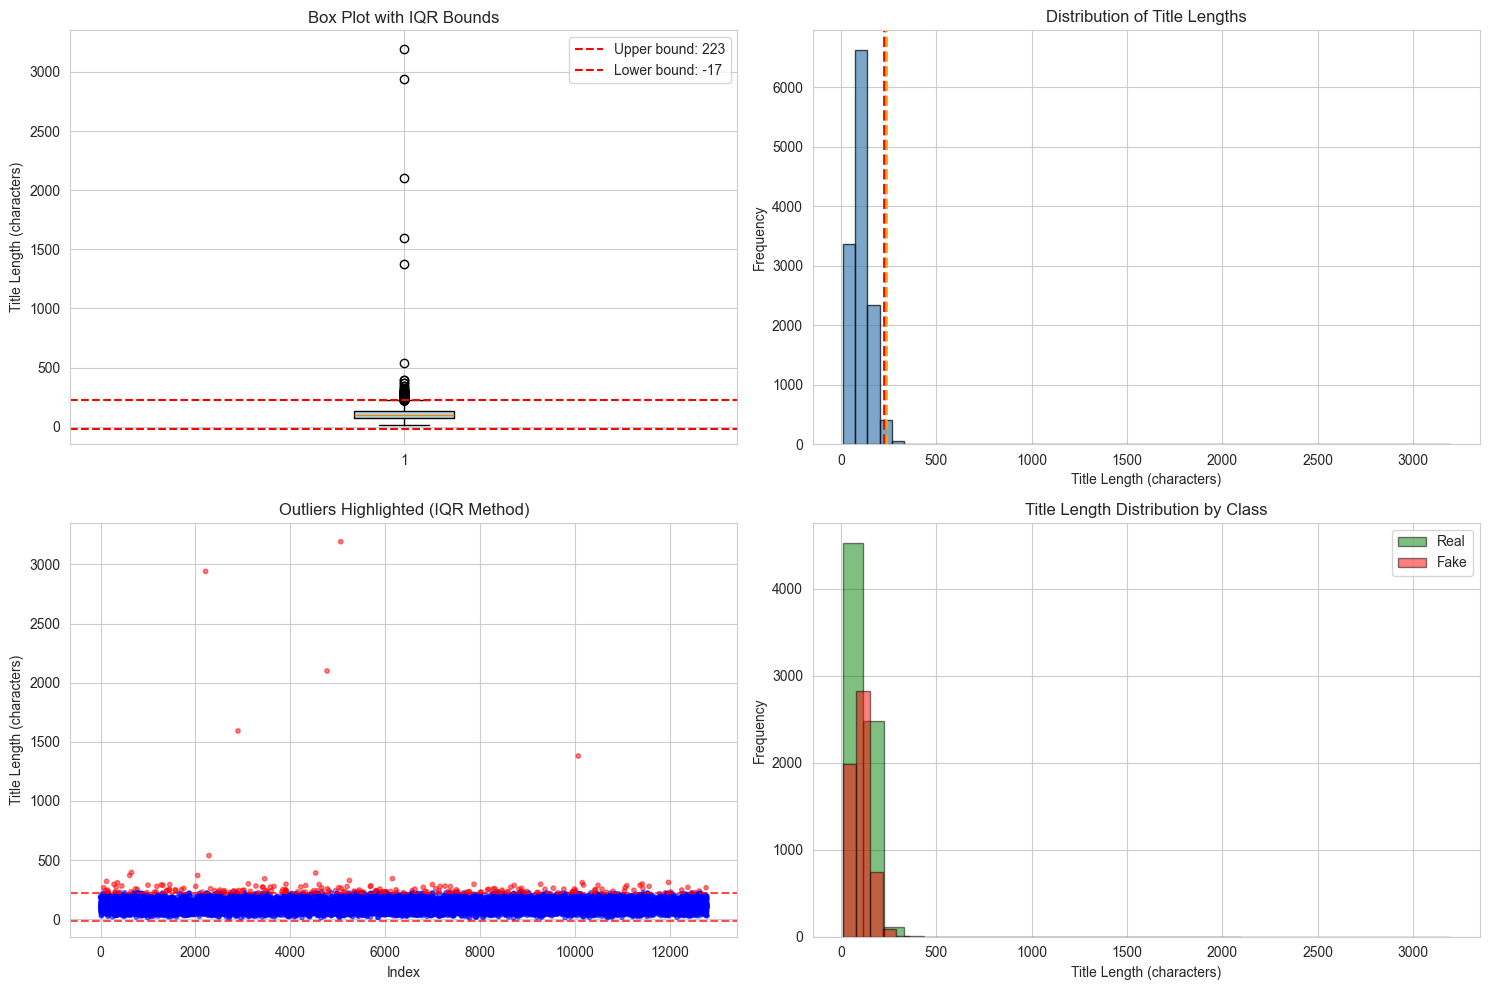


SAMPLE OF OUTLIERS (IQR Method)


,Title,Length,Label
64,The director of the FBI said that we cannot fi...,266,0
99,If you are a federally licensed gun dealer and...,243,0
124,"Since 2013 alone, the Obama administration has...",320,0
149,"John Kasich says he won, despite 12 visits by ...",246,0
155,"After filing a lawsuit in Rhode Island, we rea...",226,0
168,The University of Florida announced this past ...,229,0
282,This year President Obama canceled the 21st an...,295,1
302,"As a candidate, President Obama declared that ...",225,0
306,"Says that as Providences mayor, David Cicillin...",230,1
328,"In slashing $1.7 billion from Social Security,...",270,1



OUTLIER DETECTION SUMMARY


,Method,Total Outliers,Percentage
0,IQR,203,1.59%
1,Z-Score,19,0.15%
2,Percentile (1-99),243,1.90%
3,Modified Z-Score (MAD),84,0.66%


In [68]:
# Cell: Outlier Detection for Text Length in Title Column
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Check if title column exists
if 'title' in df.columns:
    # Calculate title length
    df['title_len'] = df['title'].astype(str).apply(len)
    
    print("Title Length Statistics:")
    print(df['title_len'].describe())
    print("\n")
    
    # ============================================
    # METHOD 1: IQR (Interquartile Range) Method
    # ============================================
    Q1 = df['title_len'].quantile(0.25)
    Q3 = df['title_len'].quantile(0.75)
    IQR = Q3 - Q1
    
    lower_bound_iqr = Q1 - 1.5 * IQR
    upper_bound_iqr = Q3 + 1.5 * IQR
    
    outliers_iqr = df[(df['title_len'] < lower_bound_iqr) | (df['title_len'] > upper_bound_iqr)]
    
    print("="*50)
    print("METHOD 1: IQR Method")
    print("="*50)
    print(f"Q1: {Q1:.2f}")
    print(f"Q3: {Q3:.2f}")
    print(f"IQR: {IQR:.2f}")
    print(f"Lower bound: {lower_bound_iqr:.2f}")
    print(f"Upper bound: {upper_bound_iqr:.2f}")
    print(f"Number of outliers: {len(outliers_iqr)} ({len(outliers_iqr)/len(df)*100:.2f}%)")
    print(f"Outlier range: < {lower_bound_iqr:.0f} or > {upper_bound_iqr:.0f} characters")
    
    # ============================================
    # METHOD 2: Z-Score Method
    # ============================================
    from scipy import stats
    
    z_scores = np.abs(stats.zscore(df['title_len'].dropna()))
    threshold_z = 3
    outliers_zscore = df.iloc[df['title_len'].dropna().index][z_scores > threshold_z]
    
    print("\n" + "="*50)
    print("METHOD 2: Z-Score Method")
    print("="*50)
    print(f"Z-score threshold: {threshold_z}")
    print(f"Number of outliers: {len(outliers_zscore)} ({len(outliers_zscore)/len(df)*100:.2f}%)")
    
    # ============================================
    # METHOD 3: Percentile Method
    # ============================================
    lower_percentile = 1
    upper_percentile = 99
    
    lower_bound_pct = df['title_len'].quantile(lower_percentile/100)
    upper_bound_pct = df['title_len'].quantile(upper_percentile/100)
    
    outliers_percentile = df[(df['title_len'] < lower_bound_pct) | (df['title_len'] > upper_bound_pct)]
    
    print("\n" + "="*50)
    print("METHOD 3: Percentile Method")
    print("="*50)
    print(f"Lower {lower_percentile}th percentile: {lower_bound_pct:.2f}")
    print(f"Upper {upper_percentile}th percentile: {upper_bound_pct:.2f}")
    print(f"Number of outliers: {len(outliers_percentile)} ({len(outliers_percentile)/len(df)*100:.2f}%)")
    
    # ============================================
    # METHOD 4: Modified Z-Score (MAD) - Robust to outliers
    # ============================================
    median = df['title_len'].median()
    mad = np.median(np.abs(df['title_len'] - median))
    modified_z_scores = 0.6745 * (df['title_len'] - median) / mad
    threshold_mad = 3.5
    outliers_mad = df[np.abs(modified_z_scores) > threshold_mad]
    
    print("\n" + "="*50)
    print("METHOD 4: Modified Z-Score (MAD)")
    print("="*50)
    print(f"Median: {median:.2f}")
    print(f"MAD: {mad:.2f}")
    print(f"Threshold: {threshold_mad}")
    print(f"Number of outliers: {len(outliers_mad)} ({len(outliers_mad)/len(df)*100:.2f}%)")
    
    # ============================================
    # VISUALIZATION
    # ============================================
    fig, axes = plt.subplots(2, 2, figsize=(15, 10))
    
    # Box plot with IQR outliers highlighted
    ax1 = axes[0, 0]
    bp = ax1.boxplot(df['title_len'].dropna(), vert=True, patch_artist=True)
    bp['boxes'][0].set_facecolor('lightblue')
    ax1.axhline(y=upper_bound_iqr, color='red', linestyle='--', label=f'Upper bound: {upper_bound_iqr:.0f}')
    ax1.axhline(y=lower_bound_iqr, color='red', linestyle='--', label=f'Lower bound: {lower_bound_iqr:.0f}')
    ax1.set_title('Box Plot with IQR Bounds')
    ax1.set_ylabel('Title Length (characters)')
    ax1.legend()
    
    # Histogram with KDE
    ax2 = axes[0, 1]
    ax2.hist(df['title_len'], bins=50, edgecolor='black', alpha=0.7, color='steelblue')
    ax2.axvline(x=upper_bound_iqr, color='red', linestyle='--', linewidth=2)
    ax2.axvline(x=upper_bound_pct, color='orange', linestyle='--', linewidth=2)
    ax2.set_title('Distribution of Title Lengths')
    ax2.set_xlabel('Title Length (characters)')
    ax2.set_ylabel('Frequency')
    
    # Scatter plot (index vs length) with outliers highlighted
    ax3 = axes[1, 0]
    colors = np.where((df['title_len'] >= lower_bound_iqr) & (df['title_len'] <= upper_bound_iqr), 'blue', 'red')
    ax3.scatter(range(len(df)), df['title_len'], c=colors, alpha=0.5, s=10)
    ax3.axhline(y=upper_bound_iqr, color='red', linestyle='--', alpha=0.7)
    ax3.axhline(y=lower_bound_iqr, color='red', linestyle='--', alpha=0.7)
    ax3.set_title('Outliers Highlighted (IQR Method)')
    ax3.set_xlabel('Index')
    ax3.set_ylabel('Title Length (characters)')
    
    # Distribution by label
    ax4 = axes[1, 1]
    for label_val, color, name in [(0, 'green', 'Real'), (1, 'red', 'Fake')]:
        subset = df[df['label'] == label_val]
        ax4.hist(subset['title_len'], bins=30, alpha=0.5, color=color, label=name, edgecolor='black')
    ax4.set_title('Title Length Distribution by Class')
    ax4.set_xlabel('Title Length (characters)')
    ax4.set_ylabel('Frequency')
    ax4.legend()
    
    plt.tight_layout()
    plt.show()
    
    # ============================================
    # SHOW SAMPLE OUTLIERS
    # ============================================
    print("\n" + "="*50)
    print("SAMPLE OF OUTLIERS (IQR Method)")
    print("="*50)
    if len(outliers_iqr) > 0:
        display(outliers_iqr[['title', 'title_len', 'label']].head(10)
               .rename(columns={'title': 'Title', 'title_len': 'Length', 'label': 'Label'}))
    else:
        print("No outliers found with IQR method.")
    
    # ============================================
    # SUMMARY TABLE
    # ============================================
    print("\n" + "="*50)
    print("OUTLIER DETECTION SUMMARY")
    print("="*50)
    summary_data = {
        'Method': ['IQR', 'Z-Score', 'Percentile (1-99)', 'Modified Z-Score (MAD)'],
        'Total Outliers': [
            len(outliers_iqr),
            len(outliers_zscore),
            len(outliers_percentile),
            len(outliers_mad)
        ],
        'Percentage': [
            f"{len(outliers_iqr)/len(df)*100:.2f}%",
            f"{len(outliers_zscore)/len(df)*100:.2f}%",
            f"{len(outliers_percentile)/len(df)*100:.2f}%",
            f"{len(outliers_mad)/len(df)*100:.2f}%"
        ]
    }
    summary_df = pd.DataFrame(summary_data)
    display(summary_df)
    
else:
    print("Error: 'title' column not found in the dataset.")
    print("Available columns:", df.columns.tolist())

In [82]:
# Optional Cell: Create outlier flag and filter dataset
# Add outlier flags to the dataset
df['is_outlier_title_len_iqr'] = (df['title_len'] < lower_bound_iqr) | (df['title_len'] > upper_bound_iqr)
df['is_outlier_title_len_zscore'] = z_scores > threshold_z

print("Sample data with outlier flags:")
display(df[['title', 'title_len', 'is_outlier_title_len_iqr', 'label']].sample(50))

# Optional: Filter out outliers
df_no_outliers = df[~df['is_outlier_title_len_iqr']]
print(f"\nOriginal dataset shape: {df.shape}")
print(f"Dataset without title length outliers: {df_no_outliers.shape}")

Sample data with outlier flags:


,title,title_len,is_outlier_title_len_iqr,label
5960,"Says that in 2008, President Barack Obama said...",230,True,0
12677,I had five of my citizens that were killed las...,89,False,0
5045,"Says Lloyd Doggett voted for the health care, ...",79,False,0
3389,Rhode Island has the worst maintained bridges ...,146,False,0
10788,"400,000 Oregonians have gained access to healt...",85,False,0
7406,Cheney is disagreeing with President Bush's po...,166,False,0
7427,"Since Rick Perry became governor, poverty rate...",129,False,0
1342,Obama wants to increase the size of government...,61,False,1
7901,Were the only advanced democracy in the world ...,86,False,0
2499,I never said that Muslims would be subject to ...,75,False,1



Original dataset shape: (12791, 8)
Dataset without title length outliers: (12588, 8)


In [84]:
# Optional Cell: Analyze outlier characteristics
print("Outlier analysis by class:")
print("="*50)
for label_val, label_name in [(0, 'Real'), (1, 'Fake')]:
    total_in_class = len(df[df['label'] == label_val])
    outliers_in_class = len(outliers_iqr[outliers_iqr['label'] == label_val])
    print(f"{label_name} news:")
    print(f"  Total articles: {total_in_class}")
    print(f"  Outliers: {outliers_in_class} ({outliers_in_class/total_in_class*100:.2f}%)")
    print(f"  Mean title length: {df[df['label']==label_val]['title_len'].mean():.2f}")
    print(f"  Outlier mean title length: {outliers_iqr[outliers_iqr['label']==label_val]['title_len'].mean() if outliers_in_class > 0 else 'N/A'}")

Outlier analysis by class:
Real news:
  Total articles: 7134
  Outliers: 123 (1.72%)
  Mean title length: 109.63
  Outlier mean title length: 319.5528455284553
Fake news:
  Total articles: 5657
  Outliers: 80 (1.41%)
  Mean title length: 104.04
  Outlier mean title length: 279.1375


REMOVING OUTLIERS: PERCENTILE METHOD (1-99)
Lower bound (1st percentile): 31.00 characters
Upper bound (99th percentile): 236.00 characters
Acceptable range: 31.00 - 236.00 characters

Total outliers detected: 243 (1.90%)
  - Fake news outliers: 114
  - Real news outliers: 129

SAMPLE OF ROWS TO BE REMOVED


,Title,Length,Label
16,"Ive created over 40,000 jobs.",29,1
64,The director of the FBI said that we cannot fi...,266,0
99,If you are a federally licensed gun dealer and...,243,0
124,"Since 2013 alone, the Obama administration has...",320,0
149,"John Kasich says he won, despite 12 visits by ...",246,0
153,Crime is down in Arizona.,25,0
248,NASCAR endorsed Trump,21,0
282,This year President Obama canceled the 21st an...,295,1
296,The fact is it's not amnesty.,29,0
328,"In slashing $1.7 billion from Social Security,...",270,1



DATASET AFTER REMOVING OUTLIERS
Original shape: (12791, 8)
New shape: (12548, 8)
Rows removed: 243 (1.90%)

Class distribution after removal:
Real news (0): 7005 (55.83%)
Fake news (1): 5543 (44.17%)

Title length statistics after removal:
count    12548.000000
mean       105.531798
std         41.766413
min         31.000000
25%         74.000000
50%         99.000000
75%        132.000000
max        236.000000
Name: title_len, dtype: float64


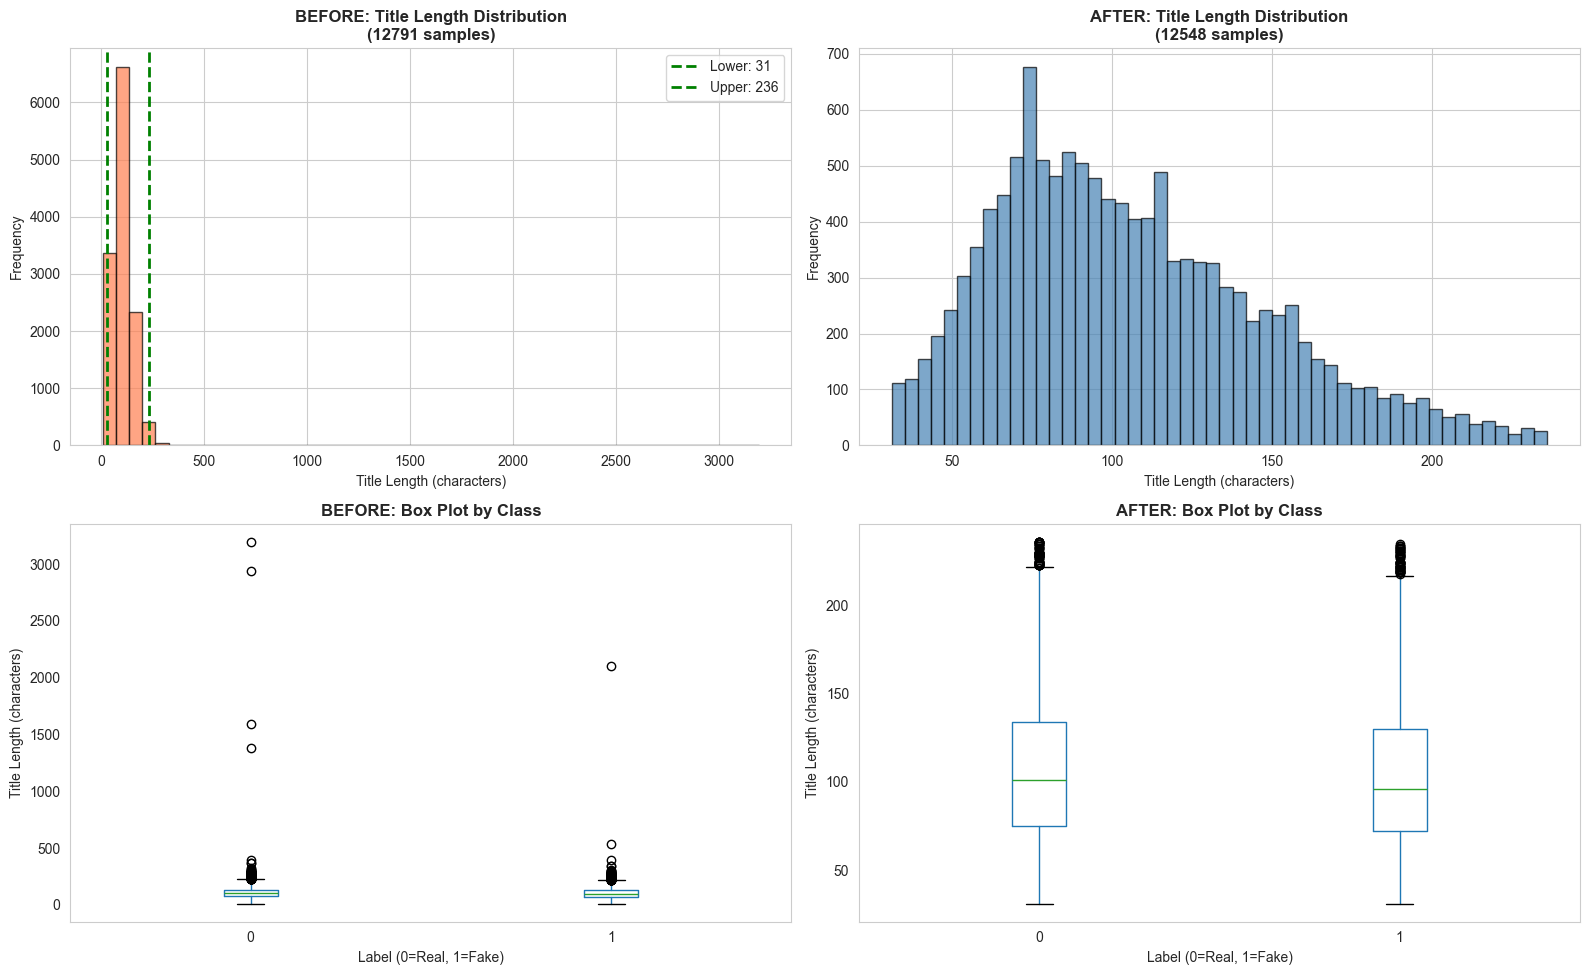


VERIFICATION
✓ SUCCESS: No outliers remaining in the cleaned dataset.

Cleaned dataset ready for use!
Variable 'df_clean' now contains the dataset without title length outliers.


In [86]:
# Cell: Remove Outliers Using Percentile (1-99) Method
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Check if title column exists and title_len has been calculated
if 'title' in df.columns and 'title_len' in df.columns:
    
    # Calculate percentile bounds
    lower_percentile = 1
    upper_percentile = 99
    
    lower_bound = df['title_len'].quantile(lower_percentile/100)
    upper_bound = df['title_len'].quantile(upper_percentile/100)
    
    print("="*60)
    print("REMOVING OUTLIERS: PERCENTILE METHOD (1-99)")
    print("="*60)
    print(f"Lower bound (1st percentile): {lower_bound:.2f} characters")
    print(f"Upper bound (99th percentile): {upper_bound:.2f} characters")
    print(f"Acceptable range: {lower_bound:.2f} - {upper_bound:.2f} characters")
    
    # Identify outliers
    outlier_mask = (df['title_len'] < lower_bound) | (df['title_len'] > upper_bound)
    num_outliers = outlier_mask.sum()
    num_removed_fake = outlier_mask[df['label'] == 1].sum()
    num_removed_real = outlier_mask[df['label'] == 0].sum()
    
    print(f"\nTotal outliers detected: {num_outliers} ({num_outliers/len(df)*100:.2f}%)")
    print(f"  - Fake news outliers: {num_removed_fake}")
    print(f"  - Real news outliers: {num_removed_real}")
    
    # Show sample of rows being removed
    print("\n" + "="*60)
    print("SAMPLE OF ROWS TO BE REMOVED")
    print("="*60)
    outliers_df = df[outlier_mask]
    if len(outliers_df) > 0:
        display(outliers_df[['title', 'title_len', 'label']].head(10)
               .rename(columns={'title': 'Title', 'title_len': 'Length', 'label': 'Label'}))
    else:
        print("No outliers to remove!")
    
    # Save original shape for comparison
    original_shape = df.shape
    
    # Remove outliers
    df_clean = df[~outlier_mask].copy()
    
    # Reset index after removal
    df_clean = df_clean.reset_index(drop=True)
    
    print("\n" + "="*60)
    print("DATASET AFTER REMOVING OUTLIERS")
    print("="*60)
    print(f"Original shape: {original_shape}")
    print(f"New shape: {df_clean.shape}")
    print(f"Rows removed: {original_shape[0] - df_clean.shape[0]} ({(original_shape[0] - df_clean.shape[0])/original_shape[0]*100:.2f}%)")
    
    # Check class distribution after removal
    print("\nClass distribution after removal:")
    print(f"Real news (0): {df_clean[df_clean['label']==0].shape[0]} ({df_clean[df_clean['label']==0].shape[0]/df_clean.shape[0]*100:.2f}%)")
    print(f"Fake news (1): {df_clean[df_clean['label']==1].shape[0]} ({df_clean[df_clean['label']==1].shape[0]/df_clean.shape[0]*100:.2f}%)")
    
    # Title length statistics after removal
    print("\nTitle length statistics after removal:")
    print(df_clean['title_len'].describe())
    
    # ============================================
    # VISUALIZATION: Before vs After
    # ============================================
    fig, axes = plt.subplots(2, 2, figsize=(16, 10))
    
    # Before - Distribution
    ax1 = axes[0, 0]
    ax1.hist(df['title_len'], bins=50, edgecolor='black', alpha=0.7, color='coral')
    ax1.axvline(x=lower_bound, color='green', linestyle='--', linewidth=2, label=f'Lower: {lower_bound:.0f}')
    ax1.axvline(x=upper_bound, color='green', linestyle='--', linewidth=2, label=f'Upper: {upper_bound:.0f}')
    ax1.set_title(f'BEFORE: Title Length Distribution\n({original_shape[0]} samples)', fontsize=12, fontweight='bold')
    ax1.set_xlabel('Title Length (characters)')
    ax1.set_ylabel('Frequency')
    ax1.legend()
    
    # After - Distribution
    ax2 = axes[0, 1]
    ax2.hist(df_clean['title_len'], bins=50, edgecolor='black', alpha=0.7, color='steelblue')
    ax2.set_title(f'AFTER: Title Length Distribution\n({df_clean.shape[0]} samples)', fontsize=12, fontweight='bold')
    ax2.set_xlabel('Title Length (characters)')
    ax2.set_ylabel('Frequency')
    
    # Before - Box plot by class
    ax3 = axes[1, 0]
    df.boxplot(column='title_len', by='label', ax=ax3, grid=False)
    ax3.set_title('BEFORE: Box Plot by Class', fontsize=12, fontweight='bold')
    ax3.set_xlabel('Label (0=Real, 1=Fake)')
    ax3.set_ylabel('Title Length (characters)')
    ax3.get_figure().suptitle('')  # Remove pandas default title
    
    # After - Box plot by class
    ax4 = axes[1, 1]
    df_clean.boxplot(column='title_len', by='label', ax=ax4, grid=False)
    ax4.set_title('AFTER: Box Plot by Class', fontsize=12, fontweight='bold')
    ax4.set_xlabel('Label (0=Real, 1=Fake)')
    ax4.set_ylabel('Title Length (characters)')
    ax4.get_figure().suptitle('')  # Remove pandas default title
    
    plt.tight_layout()
    plt.show()
    
    # ============================================
    # VERIFICATION: Check no outliers remain
    # ============================================
    remaining_outliers = df_clean[(df_clean['title_len'] < lower_bound) | (df_clean['title_len'] > upper_bound)]
    
    print("\n" + "="*60)
    print("VERIFICATION")
    print("="*60)
    if len(remaining_outliers) == 0:
        print("✓ SUCCESS: No outliers remaining in the cleaned dataset.")
    else:
        print(f"⚠ WARNING: {len(remaining_outliers)} outliers still present.")
    
    print(f"\nCleaned dataset ready for use!")
    print(f"Variable 'df_clean' now contains the dataset without title length outliers.")
    
    # Optional: Overwrite original df
    # Uncomment the next line to replace df with the cleaned version
    # df = df_clean
    
else:
    print("Error: 'title' column not found or 'title_len' not calculated.")
    print("Please run the title length calculation first:")
    print("  df['title_len'] = df['title'].astype(str).apply(len)")
    if 'title' not in df.columns:
        print("Available columns:", df.columns.tolist())

In [88]:
df_clean.head()

,title,label,text_len,word_count,unique_words,title_len,is_outlier_title_len_iqr,is_outlier_title_len_zscore
0,"In the event of a U.S. strike on Syria, the Ru...",1,183,32,25,183,False,False
1,To give the proposed economic stimulus plan so...,0,193,33,28,193,False,False
2,Its warmer on Mars than it is in parts of the ...,1,95,19,18,95,False,False
3,The health insurance plan that (members of Con...,0,139,22,21,139,False,False
4,He's promising four more years of an administr...,1,110,17,16,110,False,False


In [90]:
#drop all columns except title and label
df_clean.drop(columns=['text_len', 'word_count', 'unique_words', 'title_len','is_outlier_title_len_iqr','is_outlier_title_len_zscore'], inplace=True)

In [92]:
df_clean.head()

,title,label
0,"In the event of a U.S. strike on Syria, the Ru...",1
1,To give the proposed economic stimulus plan so...,0
2,Its warmer on Mars than it is in parts of the ...,1
3,The health insurance plan that (members of Con...,0
4,He's promising four more years of an administr...,1


In [94]:
# Cell: Preprocessing Function
import re
import string
from nltk.corpus import stopwords
from nltk.tokenize import word_tokenize
from nltk.stem import WordNetLemmatizer
import emoji
from internet_words_remover import words_remover

# Download required NLTK data (run once)
import nltk
nltk.download('stopwords', quiet=True)
nltk.download('punkt', quiet=True)
nltk.download('wordnet', quiet=True)
nltk.download('omw-1.4', quiet=True)

# Initialize NLP tools
stop_words = set(stopwords.words('english'))
wn_lem = WordNetLemmatizer()
punc = str.maketrans('', '', string.punctuation)

def preprocessing(text):
    # 1. Convert to lowercase and strip whitespace
    text = text.lower()
    text = text.strip()
    
    # 2. Remove HTML tags
    text = re.sub(pattern='<.*?>', repl='', string=text)
    
    # 3. Remove URLs
    text = re.sub(pattern=r'https?://\S+|www\.\S+', repl='', string=text)
    
    # 4. Remove punctuation
    text = text.translate(punc)
    
    # 5. Replace chat words
    text = words_remover(text)
    
    # 6. Remove stopwords
    new_text1 = []
    for word in text.split():
        if word not in stop_words:
            new_text1.append(word)
    text = ' '.join(new_text1)
    
    # 7. Convert emojis to text
    text = emoji.demojize(text)
    
    # 8. Lemmatization
    new_text2 = []
    for word in text.split():
        lemmatized_word = wn_lem.lemmatize(word, pos='v')
        new_text2.append(lemmatized_word)
    text = ' '.join(new_text2)
    
    return text

In [96]:
# Apply preprocessing
df_clean['transformed_text'] = df_clean['title'].apply(preprocessing)

print("Preprocessing completed")
print(df_clean.head())

Preprocessing completed
                                               title  label  \
0  In the event of a U.S. strike on Syria, the Ru...      1   
1  To give the proposed economic stimulus plan so...      0   
2  Its warmer on Mars than it is in parts of the ...      1   
3  The health insurance plan that (members of Con...      0   
4  He's promising four more years of an administr...      1   

                                    transformed_text  
0  event us strike syria russians replace weapons...  
1  give propose economic stimulus plan perspectiv...  
2    warmer mar part unite state canada polar vortex  
3  health insurance plan members congress differe...  
4  hes promise four years administration push pri...  


In [98]:
df_clean.to_csv('LIAR_clean.csv', index=False)

### This code for balanced (undersampled)

In [100]:
# Cell: Undersample majority class to balance dataset
import pandas as pd

# Assume df_clean is your current DataFrame with 'label' column (0=Real, 1=Fake)
print("Original class distribution:")
print(df_clean['label'].value_counts())

# Separate classes
df_class_0 = df_clean[df_clean['label'] == 0]   # majority class (adjust if Fake is majority)
df_class_1 = df_clean[df_clean['label'] == 1]

# Find minority count
minority_count = min(len(df_class_0), len(df_class_1))
print(f"\nMinority class count: {minority_count}")

# Undersample the majority class
if len(df_class_0) > minority_count:
    df_class_0_under = df_class_0.sample(n=minority_count, random_state=42)
else:
    df_class_0_under = df_class_0

if len(df_class_1) > minority_count:
    df_class_1_under = df_class_1.sample(n=minority_count, random_state=42)
else:
    df_class_1_under = df_class_1

# Combine back
df_balanced = pd.concat([df_class_0_under, df_class_1_under], ignore_index=True)
df_balanced = df_balanced.sample(frac=1, random_state=42).reset_index(drop=True)  # shuffle

print("\nBalanced class distribution:")
print(df_balanced['label'].value_counts())
print(f"New dataset shape: {df_balanced.shape}")

# Optional: overwrite df_clean for subsequent steps
# df_clean = df_balanced

Original class distribution:
label
0    7005
1    5543
Name: count, dtype: int64

Minority class count: 5543

Balanced class distribution:
label
0    5543
1    5543
Name: count, dtype: int64
New dataset shape: (11086, 3)


In [102]:
df_balanced.head()

,title,label,transformed_text
0,Women in Florida make 83 cents for every dolla...,0,women florida make 83 cents every dollar man make
1,A Republican-led softening of firearms trainin...,0,republicanled soften firearms train rule mean ...
2,Says a Pro-Stimulus economist admits it is not...,1,say prostimulus economist admit work
3,Dont believe those phony numbers when you hear...,1,dont believe phony number hear 49 5 percent un...
4,"A law was passed, apparently in the Clinton ad...",1,law pass apparently clinton administration whe...


In [110]:
df_balanced.shape

(11086, 3)

In [104]:
df_balanced.to_csv('LIAR_bal.csv', index=False)

In [112]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    df_balanced['transformed_text'], 
    df_balanced['label'],            
    test_size=0.2,               
    random_state=42,               
)

In [114]:
from sklearn.feature_extraction.text import CountVectorizer

cv = CountVectorizer()
X_train_bow = cv.fit_transform(X_train)
X_test_bow = cv.transform(X_test)

print("BoW feature extraction completed")
print("X_train shape:", X_train_bow.shape)
print("X_test shape:", X_test_bow.shape)

BoW feature extraction completed
X_train shape: (8868, 10259)
X_test shape: (2218, 10259)


In [116]:
import pickle

# Save train vectors
with open("X_train_bow.pkl", "wb") as f:
    pickle.dump(X_train_bow, f)

# Save test vectors
with open("X_test_bow.pkl", "wb") as f:
    pickle.dump(X_test_bow, f)

with open("y_train_bow.pkl", "wb") as f:
    pickle.dump(y_train, f)

with open("y_test_bow.pkl", "wb") as f:
    pickle.dump(y_test, f)

with open("count_vectorizer.pkl", "wb") as f:
    pickle.dump(cv, f)

### till above

In [118]:
df.head()

,title,label,text_len,word_count,unique_words,title_len,is_outlier_title_len_iqr,is_outlier_title_len_zscore
0,"In the event of a U.S. strike on Syria, the Ru...",1,183,32,25,183,False,False
1,To give the proposed economic stimulus plan so...,0,193,33,28,193,False,False
2,Its warmer on Mars than it is in parts of the ...,1,95,19,18,95,False,False
3,The health insurance plan that (members of Con...,0,139,22,21,139,False,False
4,He's promising four more years of an administr...,1,110,17,16,110,False,False


In [120]:
df_clean.head()

,title,label,transformed_text
0,"In the event of a U.S. strike on Syria, the Ru...",1,event us strike syria russians replace weapons...
1,To give the proposed economic stimulus plan so...,0,give propose economic stimulus plan perspectiv...
2,Its warmer on Mars than it is in parts of the ...,1,warmer mar part unite state canada polar vortex
3,The health insurance plan that (members of Con...,0,health insurance plan members congress differe...
4,He's promising four more years of an administr...,1,hes promise four years administration push pri...


### Creating Ngram

In [123]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    df_balanced['transformed_text'], 
    df_balanced['label'],            
    test_size=0.2,               
    random_state=42,               
)

In [125]:
from sklearn.feature_extraction.text import CountVectorizer

# N-gram vectorizer with unigrams and bigrams, top 5000 features
ngram_vectorizer = CountVectorizer(ngram_range=(1,2), max_features=5000)

X_train_ngram = ngram_vectorizer.fit_transform(X_train)
X_test_ngram = ngram_vectorizer.transform(X_test)

print("N-gram feature extraction completed")
print("X_train ngram shape:", X_train_ngram.shape)
print("X_test ngram shape:", X_test_ngram.shape)

N-gram feature extraction completed
X_train ngram shape: (8868, 5000)
X_test ngram shape: (2218, 5000)


In [127]:
import pickle

# Save train vectors
with open("X_train_ngram.pkl", "wb") as f:
    pickle.dump(X_train_ngram, f)

# Save test vectors
with open("X_test_ngram.pkl", "wb") as f:
    pickle.dump(X_test_ngram, f)

with open("y_train_ngram.pkl", "wb") as f:
    pickle.dump(y_train, f)

with open("y_test_ngram.pkl", "wb") as f:
    pickle.dump(y_test, f)

with open("ngrams.pkl", "wb") as f:
    pickle.dump(ngram_vectorizer, f)

### Creating TFIDF

In [130]:
from sklearn.feature_extraction.text import TfidfVectorizer

# Simple TF-IDF (unigrams only, no max_features)
tfidf = TfidfVectorizer()
X_train_tfidf = tfidf.fit_transform(X_train)
X_test_tfidf = tfidf.transform(X_test)

print("TF-IDF feature extraction completed")
print("TF-IDF X_train shape:", X_train_tfidf.shape)
print("TF-IDF X_test shape:", X_test_tfidf.shape)

TF-IDF feature extraction completed
TF-IDF X_train shape: (8868, 10259)
TF-IDF X_test shape: (2218, 10259)


In [132]:
import pickle

# Save train vectors
with open("X_train_tfidf.pkl", "wb") as f:
    pickle.dump(X_train_tfidf, f)

# Save test vectors
with open("X_test_tfidf.pkl", "wb") as f:
    pickle.dump(X_test_tfidf, f)

with open("y_train_tfidf.pkl", "wb") as f:
    pickle.dump(y_train, f)

with open("y_test_tfidf.pkl", "wb") as f:
    pickle.dump(y_test, f)

with open("tfidf.pkl", "wb") as f:
    pickle.dump(tfidf, f)

### Creating TFIDF (ngram)

In [135]:
from sklearn.feature_extraction.text import TfidfVectorizer

# TF-IDF with unigrams and bigrams, top 5000 features
tfidf_ngram = TfidfVectorizer(ngram_range=(1,2), max_features=5000)
X_train_tfidf_ngram = tfidf_ngram.fit_transform(X_train)
X_test_tfidf_ngram = tfidf_ngram.transform(X_test)

print("TF-IDF feature extraction completed")
print("TF-IDF ngram X_train shape:", X_train_tfidf_ngram.shape)
print("TF-IDF ngram X_test shape:", X_test_tfidf_ngram.shape)

TF-IDF feature extraction completed
TF-IDF ngram X_train shape: (8868, 5000)
TF-IDF ngram X_test shape: (2218, 5000)


In [137]:
import pickle

# Save train vectors
with open("X_train_tfidf_ngram.pkl", "wb") as f:
    pickle.dump(X_train_tfidf_ngram, f)

# Save test vectors
with open("X_test_tfidf_ngram.pkl", "wb") as f:
    pickle.dump(X_test_tfidf_ngram, f)

with open("y_train_tfidf_ngram.pkl", "wb") as f:
    pickle.dump(y_train, f)

with open("y_test_tfidf_ngram.pkl", "wb") as f:
    pickle.dump(y_test, f)

with open("tfidf_ngram.pkl", "wb") as f:
    pickle.dump(tfidf_ngram, f)

### Creating pos tagging

In [140]:
# POS tag features combined with Bag-of-Words
import nltk
from nltk import word_tokenize, pos_tag
from collections import Counter
from scipy.sparse import hstack
import pandas as pd

# Ensure required NLTK data is available (run once)
nltk.download('punkt', quiet=True)
nltk.download('averaged_perceptron_tagger_eng', quiet=True)

# Functions to extract POS tags and count features
def get_pos_tags(text):
    tokens = word_tokenize(text)
    return pos_tag(tokens)

def pos_features(pos_tags):
    counts = Counter(tag for (word, tag) in pos_tags)
    feature_dict = {
        'nouns': counts.get('NN',0) + counts.get('NNS',0) + counts.get('NNP',0) + counts.get('NNPS',0),
        'verbs': counts.get('VB',0) + counts.get('VBD',0) + counts.get('VBG',0) + counts.get('VBN',0) +
                 counts.get('VBP',0) + counts.get('VBZ',0),
        'adjectives': counts.get('JJ',0) + counts.get('JJR',0) + counts.get('JJS',0),
        'adverbs': counts.get('RB',0) + counts.get('RBR',0) + counts.get('RBS',0)
    }
    return feature_dict

# Apply POS extraction to training and test texts
print("Extracting POS tags from training data...")
train_pos_tags = X_train.apply(get_pos_tags)
test_pos_tags = X_test.apply(get_pos_tags)

print("Computing POS features...")
train_pos_feat = train_pos_tags.apply(pos_features)
test_pos_feat = test_pos_tags.apply(pos_features)

# Convert the dictionary Series into DataFrames
df_train_pos = pd.DataFrame(list(train_pos_feat))
df_test_pos = pd.DataFrame(list(test_pos_feat))

# Create BoW features (unigrams) using CountVectorizer
bow_vectorizer = CountVectorizer()
X_train_bow_pos = bow_vectorizer.fit_transform(X_train)
X_test_bow_pos = bow_vectorizer.transform(X_test)

# Combine BoW matrix with POS dense features using hstack
X_train_pos_bow = hstack([X_train_bow_pos, df_train_pos.values])
X_test_pos_bow = hstack([X_test_bow_pos, df_test_pos.values])

print("POS + BOW features completed")
print("X_train shape:", X_train_pos_bow.shape)
print("X_test shape:", X_test_pos_bow.shape)

Extracting POS tags from training data...
Computing POS features...
POS + BOW features completed
X_train shape: (8868, 10263)
X_test shape: (2218, 10263)


In [142]:
import pickle

# Save train vectors
with open("X_train_pos_bow.pkl", "wb") as f:
    pickle.dump(X_train_pos_bow, f)

# Save test vectors
with open("X_test_pos_bow.pkl", "wb") as f:
    pickle.dump(X_test_pos_bow, f)

with open("y_train_pos.pkl", "wb") as f:
    pickle.dump(y_train, f)

with open("y_test_pos.pkl", "wb") as f:
    pickle.dump(y_test, f)